In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
PROJECT_ROOT = Path("..")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"

MODELS_DIR.mkdir(parents=True, exist_ok=True)

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
X_train = pd.read_csv(PROCESSED_DIR / "X_train_raw_baseline.csv")

X_test = pd.read_csv(PROCESSED_DIR / "X_test_raw_baseline.csv")

y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv").squeeze("columns")

y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv").squeeze("columns")

In [4]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (54533, 11)
X_test : (13634, 11)
y_train: (54533,)
y_test : (13634,)


In [5]:
NUMERICAL_FEATURES = ["age_years", "height", "weight", "ap_hi", "ap_lo"]

CATEGORICAL_FEATURES = ["gender", "cholesterol", "gluc", "smoke", "alco", "active"]

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERICAL_FEATURES),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            CATEGORICAL_FEATURES,
        ),
    ]
)

In [ ]:
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(max_iter=1000, random_state=42),
        ),
    ]
)

In [ ]:
random_forest_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            ColumnTransformer(
                transformers=[
                    ("num", "passthrough", NUMERICAL_FEATURES),
                    (
                        "cat",
                        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                        CATEGORICAL_FEATURES,
                    ),
                ]
            ),
        ),
        (
            "classifier",
            RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
        ),
    ]
)

In [ ]:
hist_gradient_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            ColumnTransformer(
                transformers=[
                    ("num", "passthrough", NUMERICAL_FEATURES),
                    (
                        "cat",
                        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                        CATEGORICAL_FEATURES,
                    ),
                ]
            ),
        ),
        (
            "classifier",
            HistGradientBoostingClassifier(
                max_iter=200, learning_rate=0.05, max_leaf_nodes=31, random_state=42
            ),
        ),
    ]
)

In [10]:
models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": random_forest_pipeline,
    "HistGradientBoosting": hist_gradient_pipeline,
}

In [11]:
for name in models:
    print(name)

Logistic Regression
Random Forest
HistGradientBoosting


In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [13]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

In [14]:
cv_results = {}

for name, model in models.items():

    print(f"Running: {name}")

    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False,
    )

    cv_results[name] = results

Running: Logistic Regression
Running: Random Forest
Running: HistGradientBoosting


In [15]:
comparison_rows = []

for name, results in cv_results.items():

    row = {"model": name}

    for metric in scoring:

        values = results[f"test_{metric}"]

        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std()

    comparison_rows.append(row)

cv_comparison = pd.DataFrame(comparison_rows)

cv_comparison

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
0,Logistic Regression,0.726569,0.003182,0.753704,0.003163,0.662742,0.006982,0.705282,0.004395,0.790517,0.003581,0.770050,0.004898
1,Random Forest,0.703629,0.003107,0.702590,0.003033,0.693088,0.005625,0.697797,0.003697,0.761694,0.002985,0.741476,0.005582
2,HistGradientBoosting,0.733959,0.002600,0.752621,0.003981,0.686959,0.004920,0.718276,0.002911,0.799693,0.003858,0.781378,0.003993


In [16]:
display_table = cv_comparison.copy()

for column in display_table.columns:

    if column != "model":
        display_table[column] = display_table[column].round(4)

display_table

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
0,Logistic Regression,0.7266,0.0032,0.7537,0.0032,0.6627,0.0070,0.7053,0.0044,0.7905,0.0036,0.7701,0.0049
1,Random Forest,0.7036,0.0031,0.7026,0.0030,0.6931,0.0056,0.6978,0.0037,0.7617,0.0030,0.7415,0.0056
2,HistGradientBoosting,0.7340,0.0026,0.7526,0.0040,0.6870,0.0049,0.7183,0.0029,0.7997,0.0039,0.7814,0.0040


In [17]:
fitted_models = {}

for name, model in models.items():

    print(f"Training: {name}")

    model.fit(
        X_train,
        y_train,
    )

    fitted_models[name] = model

Training: Logistic Regression
Training: Random Forest
Training: HistGradientBoosting


In [ ]:
test_predictions = {}

for name, model in fitted_models.items():

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    test_predictions[name] = {"y_pred": y_pred, "y_prob": y_prob}

In [ ]:
test_rows = []

for name, predictions in test_predictions.items():

    y_pred = predictions["y_pred"]
    y_prob = predictions["y_prob"]

    test_rows.append(
        {
            "model": name,
            "accuracy": accuracy_score(y_test, y_pred),
            "precision": precision_score(y_test, y_pred),
            "recall": recall_score(y_test, y_pred),
            "f1": f1_score(y_test, y_pred),
            "roc_auc": roc_auc_score(y_test, y_prob),
            "pr_auc": average_precision_score(y_test, y_prob),
        }
    )

test_comparison = pd.DataFrame(test_rows)

In [20]:
test_comparison.round(4)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,0.7313,0.7604,0.6653,0.7097,0.7938,0.7736
1,Random Forest,0.7124,0.7103,0.7049,0.7076,0.7669,0.7441
2,HistGradientBoosting,0.7367,0.7534,0.6937,0.7223,0.8038,0.7849


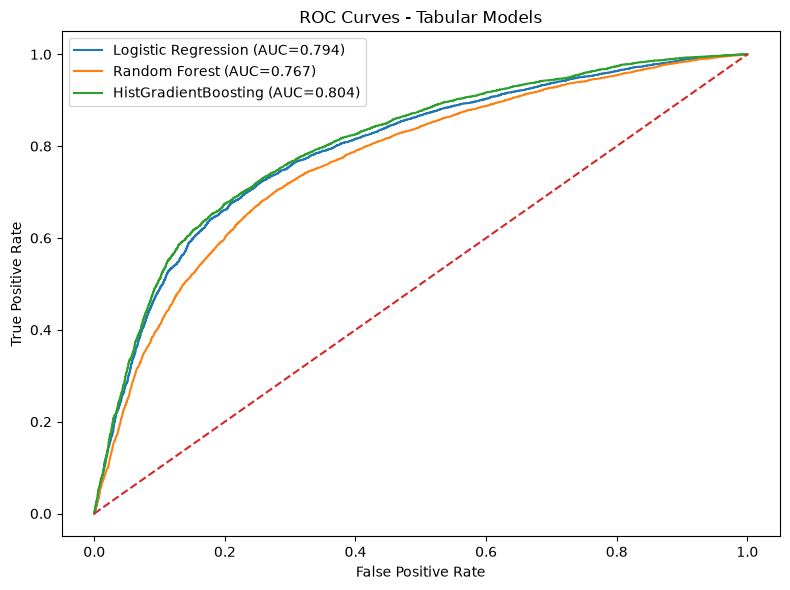

In [ ]:
plt.figure(figsize=(8, 6))

for name, predictions in test_predictions.items():

    y_prob = predictions["y_prob"]

    from sklearn.metrics import roc_curve

    fpr, tpr, _ = roc_curve(y_test, y_prob)

    auc = roc_auc_score(y_test, y_prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Tabular Models")
plt.legend()
plt.tight_layout()
plt.show()

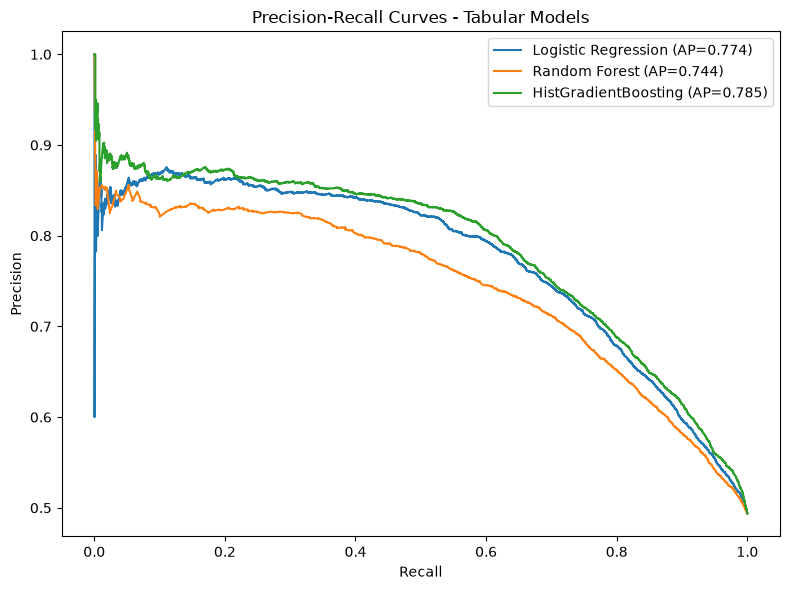

In [ ]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8, 6))

for name, predictions in test_predictions.items():

    y_prob = predictions["y_prob"]

    precision, recall, _ = precision_recall_curve(y_test, y_prob)

    ap = average_precision_score(y_test, y_prob)

    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - Tabular Models")
plt.legend()
plt.tight_layout()
plt.show()

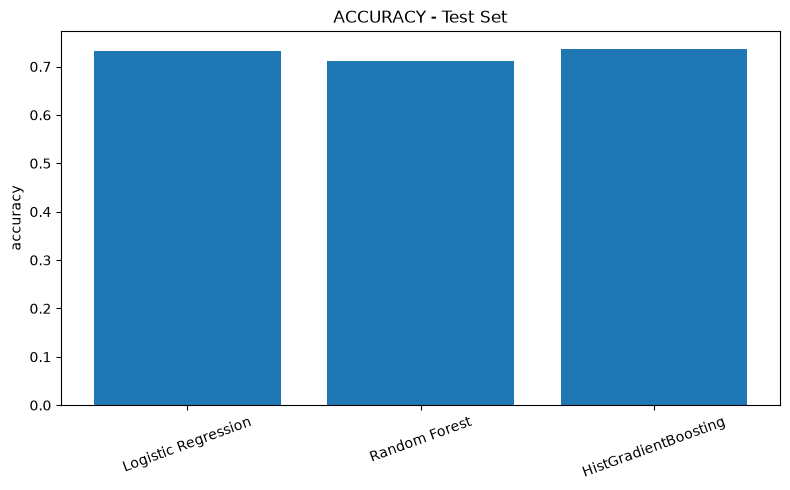

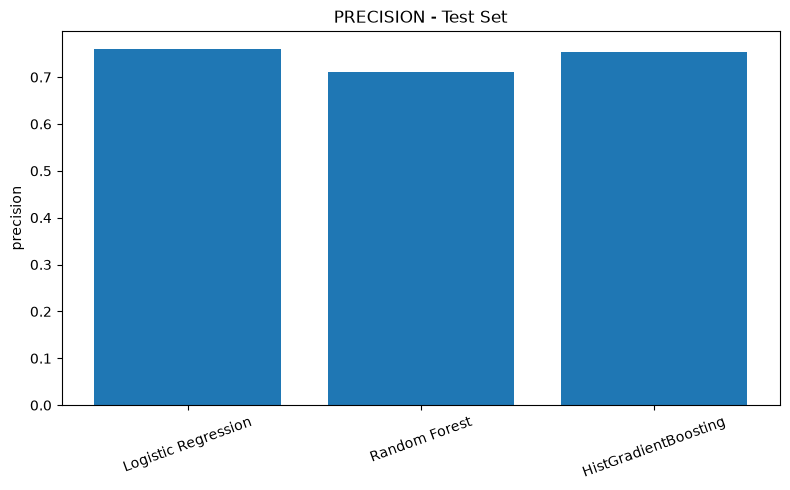

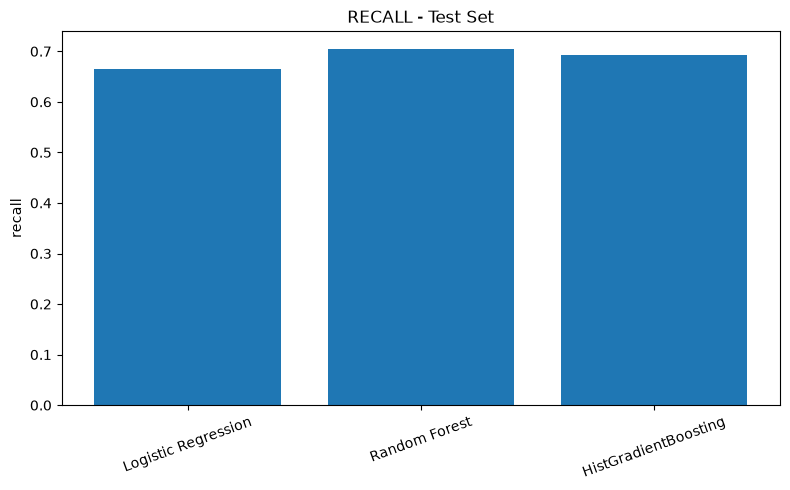

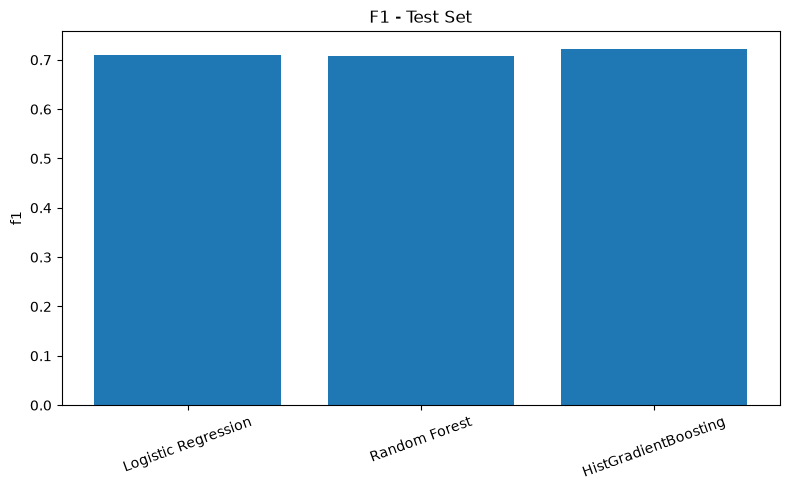

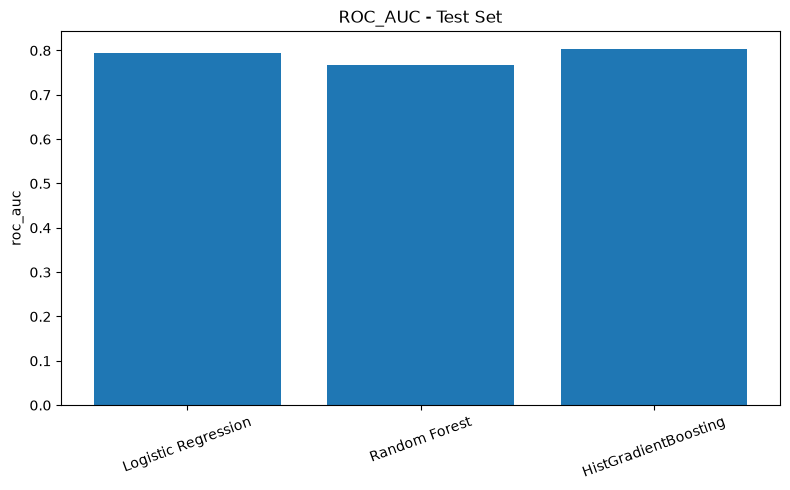

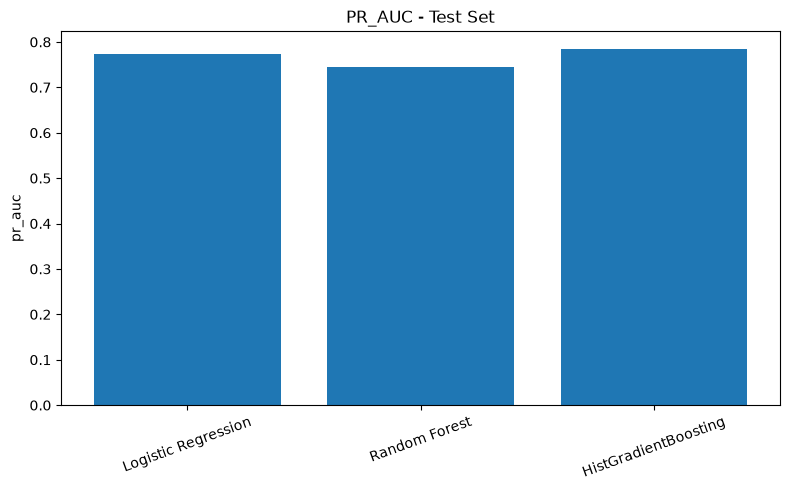

In [ ]:
metrics_to_plot = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]

for metric in metrics_to_plot:

    plt.figure(figsize=(8, 5))

    plt.bar(test_comparison["model"], test_comparison[metric])

    plt.ylabel(metric)
    plt.title(f"{metric.upper()} - Test Set")

    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

In [24]:
cv_comparison.to_csv(REPORTS_DIR / "tabular_model_cv_comparison.csv", index=False)

test_comparison.to_csv(REPORTS_DIR / "tabular_model_test_comparison.csv", index=False)

In [ ]:
for name, model in fitted_models.items():

    filename = name.lower().replace(" ", "_").replace("-", "_")

    joblib.dump(model, MODELS_DIR / f"{filename}.joblib")

In [ ]:
for name, predictions in test_predictions.items():

    filename = name.lower().replace(" ", "_").replace("-", "_")

    prediction_df = pd.DataFrame(
        {
            "y_true": y_test.to_numpy(),
            "y_pred": predictions["y_pred"],
            "y_probability": predictions["y_prob"],
        }
    )

    prediction_df.to_csv(REPORTS_DIR / f"{filename}_predictions.csv", index=False)

In [ ]:
summary = {
    "cv": cv_comparison.to_dict(orient="records"),
    "test": test_comparison.to_dict(orient="records"),
}

with open(REPORTS_DIR / "tabular_model_comparison.json", "w") as f:
    json.dump(summary, f, indent=4)

In [28]:
print("TABULAR MODEL COMPARISON")
print("=" * 50)

print("\nCross-validation:")
display(cv_comparison.round(4))

print("\nTest set:")
display(test_comparison.round(4))

TABULAR MODEL COMPARISON

Cross-validation:


,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
0,Logistic Regression,0.7266,0.0032,0.7537,0.0032,0.6627,0.0070,0.7053,0.0044,0.7905,0.0036,0.7701,0.0049
1,Random Forest,0.7036,0.0031,0.7026,0.0030,0.6931,0.0056,0.6978,0.0037,0.7617,0.0030,0.7415,0.0056
2,HistGradientBoosting,0.7340,0.0026,0.7526,0.0040,0.6870,0.0049,0.7183,0.0029,0.7997,0.0039,0.7814,0.0040



Test set:


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,0.7313,0.7604,0.6653,0.7097,0.7938,0.7736
1,Random Forest,0.7124,0.7103,0.7049,0.7076,0.7669,0.7441
2,HistGradientBoosting,0.7367,0.7534,0.6937,0.7223,0.8038,0.7849
